In [ ]:
"""
Genome and Transcriptome Description Analysis

This script analyzes gene type distribution in both genome and transcriptome
using donut plots to visualize the proportion of different gene types.
"""

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import anndata as ad
from typing import Dict, Tuple, List

In [ ]:
# Constants
GENE_TYPE_COLORS = {
    "mRNA": "#E74C3C",  # Bright red
    "rRNA": "#3498DB",  # Bright blue
    "tRNA": "#F39C12",  # Orange
    "other": "#27AE60",  # Green
}

GENE_TYPE_MAPPING = {
    "protein-coding": "mRNA",
    "tRNA": "tRNA",
    "rRNA": "rRNA",
}

# File paths
DATA_PATH = "data/Anndata/with_metadata/"
NCBI_DATA_PATH = "data/genome_annotation/ncbi_dataset_with_id.tsv"
INPUT_FILE = "GeneFull_raw_unique_mult_with_metadata.h5ad"

In [ ]:
# Set working directory to project root
os.chdir(os.path.dirname(os.path.dirname(os.path.dirname(os.path.abspath(__file__)))))

In [ ]:
def transform_gene_type(gene_type: str) -> str:
    """
    Transform gene types according to simplified classification.

    Args:
        gene_type (str): Original gene type

    Returns:
        str: Transformed gene type (mRNA, tRNA, rRNA, or other)
    """
    return GENE_TYPE_MAPPING.get(gene_type, "other")


def load_and_process_ncbi_data(file_path: str) -> pd.DataFrame:
    """
    Load and process NCBI dataset with gene type transformation.

    Args:
        file_path (str): Path to NCBI dataset file

    Returns:
        pd.DataFrame: Processed dataset with transformed gene types
    """
    print("📊 Loading NCBI dataset...")
    ncbi_data = pd.read_csv(file_path, sep="\t")

    print(f"📋 Dataset loaded with {len(ncbi_data):,} rows")
    print(f"📋 Columns: {ncbi_data.columns.tolist()}")

    # Transform gene types
    ncbi_data["Gene Type Transformed"] = ncbi_data["Gene Type"].apply(
        transform_gene_type
    )

    # Print distributions
    print_gene_type_distribution(ncbi_data, "Gene Type", "Original")
    print_gene_type_distribution(ncbi_data, "Gene Type Transformed", "Transformed")

    return ncbi_data


def print_gene_type_distribution(
    df: pd.DataFrame, column: str, description: str
) -> None:
    """
    Print gene type distribution statistics.

    Args:
        df (pd.DataFrame): DataFrame containing gene type data
        column (str): Column name with gene types
        description (str): Description for the distribution
    """
    gene_type_counts = df[column].value_counts()
    print(f"\n🧬 {description} Gene Type distribution:")
    for gene_type, count in gene_type_counts.items():
        percentage = (count / len(df)) * 100
        print(f"   {gene_type}: {count:,} genes ({percentage:.1f}%)")


def create_donut_plot(
    data: pd.Series,
    title: str,
    center_text: str,
    legend_title: str,
    unit: str = "genes",
) -> None:
    """
    Create a donut plot for gene type distribution.

    Args:
        data (pd.Series): Data to plot (gene type counts)
        title (str): Plot title
        center_text (str): Text to display in center
        legend_title (str): Title for legend
        unit (str): Unit for legend labels
    """
    # Prepare colors
    plot_colors = [
        GENE_TYPE_COLORS.get(gene_type, "#95A5A6") for gene_type in data.index
    ]

    # Create figure
    fig, ax = plt.subplots(figsize=(10, 8))

    # Create donut plot
    wedges, texts = ax.pie(
        data.values,
        startangle=90,
        colors=plot_colors,
        radius=1.0,
        wedgeprops=dict(width=0.4, edgecolor="white"),
    )

    # Add central circle
    centre_circle = plt.Circle((0, 0), 0.6, fc="white")
    ax.add_artist(centre_circle)

    # Add center text
    ax.text(
        0,
        0,
        center_text,
        ha="center",
        va="center",
        fontsize=14,
        fontweight="bold",
        color="#2C3E50",
    )

    # Add labels with smart positioning
    add_smart_labels(ax, wedges, data.index)

    # Add title
    plt.title(title, fontsize=16, fontweight="bold")

    # Add legend
    create_legend(ax, data, unit)

    plt.tight_layout()
    plt.show()


def add_smart_labels(ax: plt.Axes, wedges: List, labels: List[str]) -> None:
    """
    Add labels to donut plot with smart positioning to avoid overlaps.

    Args:
        ax (plt.Axes): Matplotlib axes object
        wedges (List): List of wedge objects from pie plot
        labels (List[str]): List of labels to add
    """
    label_positions = []

    for wedge, label in zip(wedges, labels):
        # Calculate angle and position
        angle = (wedge.theta2 + wedge.theta1) / 2.0
        x = np.cos(np.radians(angle)) * 0.85
        y = np.sin(np.radians(angle)) * 0.85

        # Avoid overlap with previous labels
        for prev_x, prev_y in label_positions:
            if abs(y - prev_y) < 0.1 and abs(x - prev_x) < 0.3:
                y += 0.15

        label_positions.append((x, y))

        # Add label
        ax.text(
            x,
            y,
            label,
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.2",
                fc="white",
                ec=GENE_TYPE_COLORS.get(label, "gray"),
                lw=2,
                alpha=0.8,
            ),
        )


def create_legend(ax: plt.Axes, data: pd.Series, unit: str) -> None:
    """
    Create legend with counts and percentages.

    Args:
        ax (plt.Axes): Matplotlib axes object
        data (pd.Series): Data series with counts
        unit (str): Unit for legend labels
    """
    total = data.sum()
    legend_elements = []

    for gene_type, count in data.items():
        percentage = (count / total) * 100
        legend_elements.append(
            plt.Rectangle(
                (0, 0),
                1,
                1,
                facecolor=GENE_TYPE_COLORS.get(gene_type, "#95A5A6"),
                label=f"{gene_type}: {count:,} {unit} ({percentage:.1f}%)",
            )
        )

    ax.legend(
        handles=legend_elements,
        loc="center left",
        bbox_to_anchor=(1.05, 0.5),
        fontsize=11,
        title="Gene Types",
    )


def process_anndata_gene_types(adata: ad.AnnData) -> pd.Series:
    """
    Process gene types in AnnData object and calculate expression sums.

    Args:
        adata (ad.AnnData): AnnData object with gene information

    Returns:
        pd.Series: Expression sums by gene type
    """
    print("🔧 Processing gene types in transcriptome data...")

    # Create simplified gene type column
    adata.var["Gene Type simplified"] = adata.var["Gene Type"].apply(
        transform_gene_type
    )

    print("Gene Type simplified distribution:")
    print(adata.var["Gene Type simplified"].value_counts())

    # Calculate expression sums
    gene_expression_counts = pd.Series(
        np.array(adata.X.sum(axis=0)).flatten(), index=adata.var_names
    )
    adata.var["ncount"] = gene_expression_counts

    # Group by gene type
    expression_by_gene_type = (
        adata.var.groupby("Gene Type simplified")["ncount"]
        .sum()
        .sort_values(ascending=False)
    )

    print("Expression by gene type (transcriptome):")
    print(expression_by_gene_type)

    return expression_by_gene_type


def main():
    """Main analysis function."""
    print("🚀 Starting genome and transcriptome description analysis...")

    # Load and process NCBI data
    ncbi_data = load_and_process_ncbi_data(NCBI_DATA_PATH)

    # Create genome donut plot
    print("\n🍩 Creating genome donut plot...")
    genome_gene_counts = ncbi_data["Gene Type Transformed"].value_counts()
    total_genes = genome_gene_counts.sum()

    create_donut_plot(
        data=genome_gene_counts,
        title="Different types of genes in genome of Ps R401",
        center_text=f"Total number of genes\n{total_genes:,}",
        legend_title="Gene Types",
        unit="genes",
    )

    # Load and process transcriptome data
    print("\n📊 Loading transcriptome data...")
    adata = ad.read_h5ad(os.path.join(DATA_PATH, INPUT_FILE))

    # Process gene types and get expression data
    expression_by_gene_type = process_anndata_gene_types(adata)

    # Create transcriptome donut plot
    print("\n🍩 Creating transcriptome donut plot...")
    total_umis = expression_by_gene_type.sum()

    create_donut_plot(
        data=expression_by_gene_type,
        title="Number of UMIs per gene type in transcriptome of Ps R401",
        center_text=f"{int(total_umis):,}\nUMIs",
        legend_title="Gene Types",
        unit="UMIs",
    )

    print("✅ Analysis completed successfully!")

🚀 Starting genome and transcriptome description analysis...
📊 Loading NCBI dataset...
📋 Dataset loaded with 6,249 rows
📋 Columns: ['Locus tag', 'final_gene_name', 'symbol_renamed', 'Gene Type', 'Name', 'Protein accession', 'symbol_old', 'locus_tag_old']

🧬 Original Gene Type distribution:
   protein-coding: 6,100 genes (97.6%)
   tRNA: 65 genes (1.0%)
   pseudogene: 63 genes (1.0%)
   rRNA: 16 genes (0.3%)
   other: 3 genes (0.0%)
   RNase_P_RNA: 1 genes (0.0%)
   ncRNA: 1 genes (0.0%)

🧬 Transformed Gene Type distribution:
   mRNA: 6,100 genes (97.6%)
   other: 68 genes (1.1%)
   tRNA: 65 genes (1.0%)
   rRNA: 16 genes (0.3%)

🍩 Creating genome donut plot...


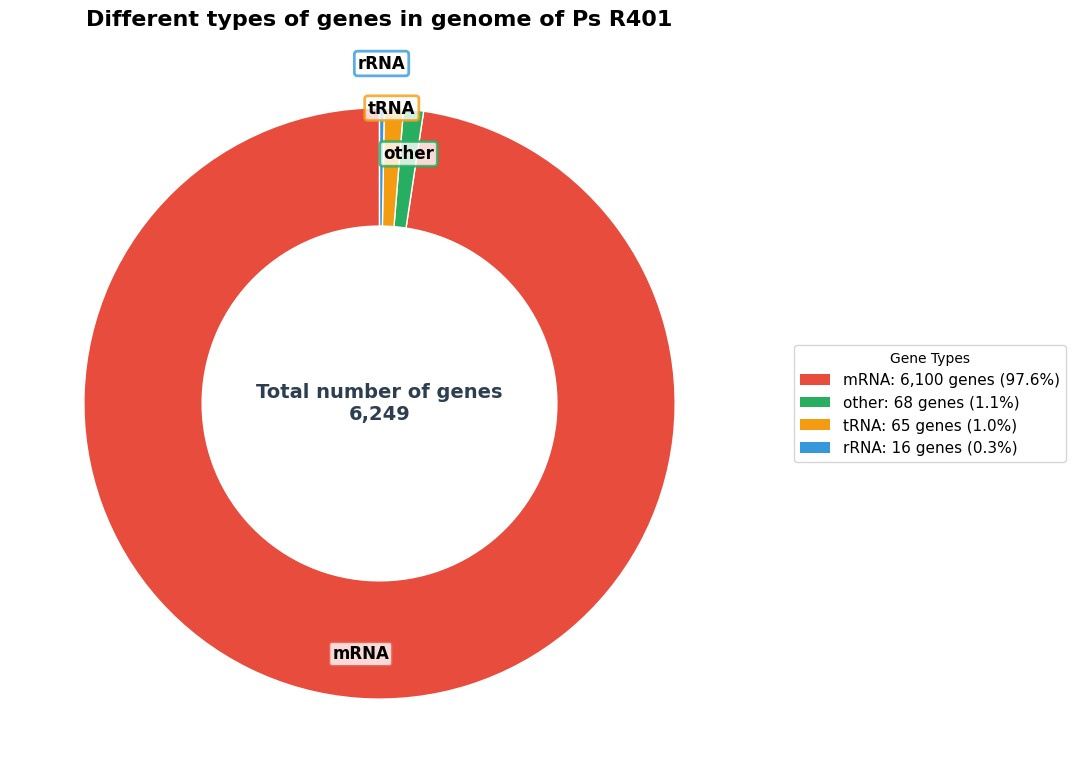


📊 Loading transcriptome data...
🔧 Processing gene types in transcriptome data...
Gene Type simplified distribution:
Gene Type simplified
mRNA     6099
other      68
tRNA       65
rRNA       16
Name: count, dtype: int64
Expression by gene type (transcriptome):
Gene Type simplified
mRNA     27114010
rRNA     17543884
tRNA      4856729
other     2074130
Name: ncount, dtype: int64

🍩 Creating transcriptome donut plot...


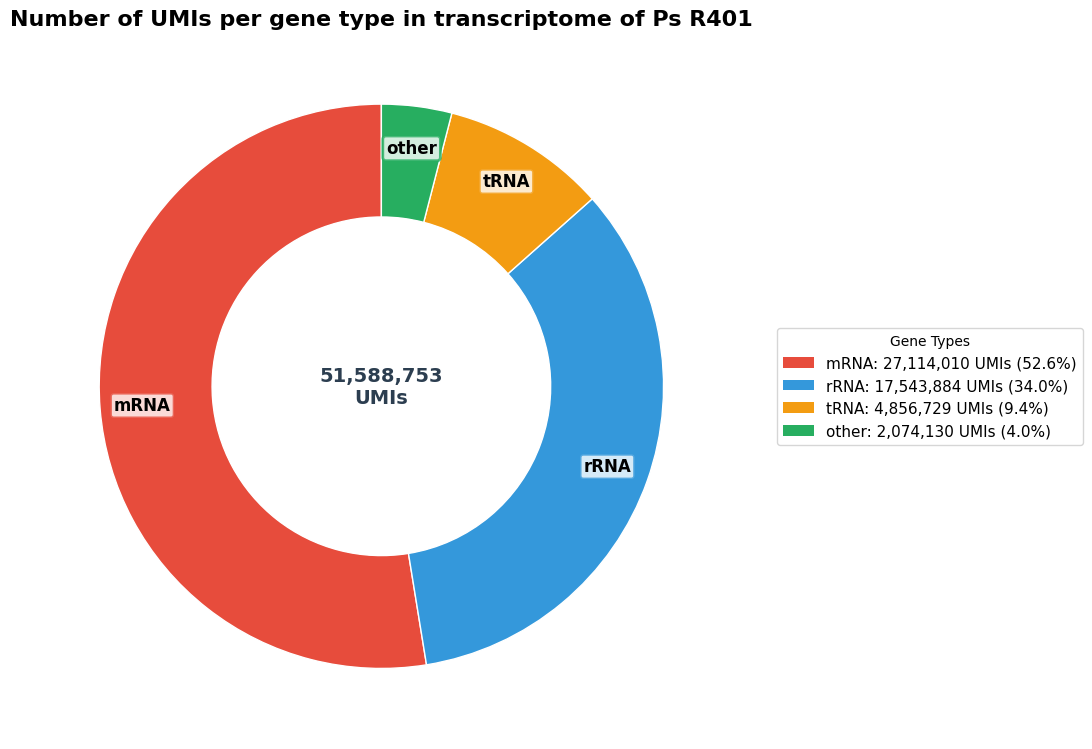

✅ Analysis completed successfully!


In [ ]:
if __name__ == "__main__":
    main()